# Linear Regression Diagnostics

### Rebuild the modeling data and select features

The data preparation from the model notebook is repeated here in the same order so the results match. The 34 features are the ones chosen by backward, forward and stepwise selection, which all agreed on the same variables.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
df = pd.read_csv("../data/cleaned/listings_features.csv")

# Same preprocessing as the model notebook, in the same order, so the results match

# Drop rows with a missing target
df = df.dropna(subset=['log_price']).copy()

# Convert bathroom text to a number and a shared-bath flag
txt = df['bathrooms_text'].str.lower()
df['bathrooms'] = txt.str.extract(r'(\d+\.?\d*)')[0].astype(float)
df.loc[txt.str.contains('half', na=False) & df['bathrooms'].isnull(), 'bathrooms'] = 0.5
df['shared_bath'] = txt.str.contains('shared', na=False).astype(int)
df = df.drop(columns=['bathrooms_text'])

# No listing sleeps more than 16 guests, so more than 16 bedrooms or bathrooms is a data error
# Listings with a missing value are kept (NaN > 16 is False) and imputed after the split
too_big = (df['bedrooms'] > 16) | (df['bathrooms'] > 16)
print("Removed listings:", too_big.sum())
df = df[~too_big].copy()
print(df.shape)

# Train/test split (same seed and size as the model notebook)
train, test = train_test_split(df, test_size=0.25, random_state=1234)

# Set target and drop non-predictors
X = train.drop(columns=['log_price', 'price_quote_price_per_night', 'price_outlier_flag']).copy()
y = train['log_price']

# Impute missing continuous values with train medians (saved for the test set later)
medians = {}
for col in X.select_dtypes(include='number').columns:
    if X[col].isnull().any():
        X[f'{col}_was_missing'] = X[col].isnull().astype(int)
        medians[col] = X[col].median()
        X[col] = X[col].fillna(medians[col])

# Dummy variables
X = pd.get_dummies(X, drop_first=True).astype(float)

# Keep the 34 features chosen by backward, forward and stepwise selection
selected_features = ['accommodates', 'bedrooms', 'minimum_nights', 'review_scores_rating', 'calculated_host_listings_count', 'has_hot_tub', 'has_gym', 'has_game_room', 'pets_allowed', 'has_city_skyline_view', 'bathrooms', 'shared_bath', 'review_scores_rating_was_missing', 'host_is_superhost_t', 'neighbourhood_cleansed_District 10', 'neighbourhood_cleansed_District 13', 'neighbourhood_cleansed_District 15', 'neighbourhood_cleansed_District 16', 'neighbourhood_cleansed_District 19', 'neighbourhood_cleansed_District 2', 'neighbourhood_cleansed_District 26', 'neighbourhood_cleansed_District 29', 'neighbourhood_cleansed_District 32', 'neighbourhood_cleansed_District 33', 'neighbourhood_cleansed_District 5', 'neighbourhood_cleansed_District 9', 'distance_band_10+ km', 'distance_band_3-5 km', 'distance_band_5-10 km', 'room_type_grouped_Room', 'property_group_Hotel/Resort', 'property_group_House', 'property_group_Other', 'property_group_Townhouse']
X_reduced = X[selected_features]

# Check
print(X_reduced.shape, y.shape)

Removed listings: 26
(8171, 26)
(6128, 34) (6128,)


### Model from Stepwise Selection

In [2]:
import statsmodels.api as sm

# Subset the DataFrame to selected features
X_selected = X_reduced[selected_features].copy()
X_selected = sm.add_constant(X_selected)
model = sm.OLS(y, X_selected).fit()

# Summary with p-values, coefficients, R², etc.
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.603
Model:                            OLS   Adj. R-squared:                  0.600
Method:                 Least Squares   F-statistic:                     271.8
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:08:55   Log-Likelihood:                -2840.7
No. Observations:                6128   AIC:                             5751.
Df Residuals:                    6093   BIC:                             5987.
Df Model:                          34                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

### Residuals

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

fitted = model.fittedvalues
residuals = model.resid
standardized_residuals = residuals / np.sqrt(model.mse_resid) 

### Lack-of-Fit

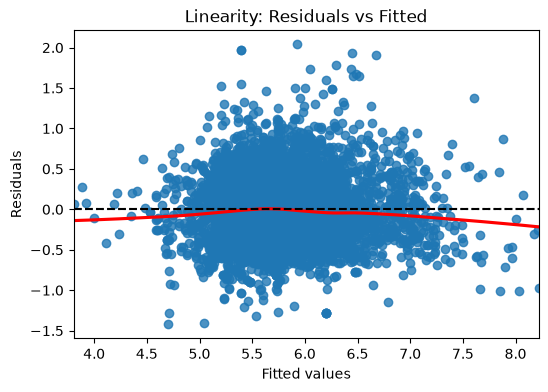

In [4]:
plt.figure(figsize=(6, 4))
sns.residplot(x=fitted, y=residuals, lowess=True, line_kws={'color': 'red'})
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Linearity: Residuals vs Fitted")
plt.show()

### Unequal Variance

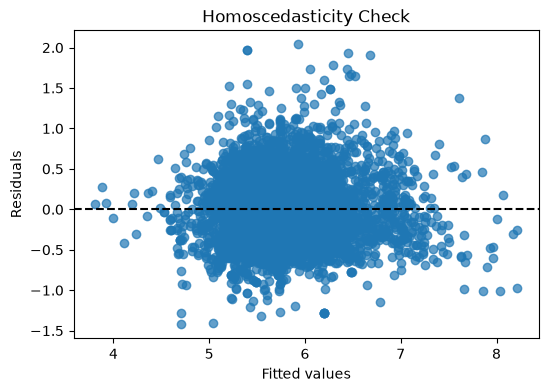

Breusch-Pagan test: p-value = 0.0000000


In [5]:
plt.figure(figsize=(6, 4))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Check")
plt.show()

# Breusch-Pagan test
from statsmodels.stats.diagnostic import het_breuschpagan
bp_test = het_breuschpagan(residuals, model.model.exog)
print(f"Breusch-Pagan test: p-value = {bp_test[1]:.7f}")

### Normality

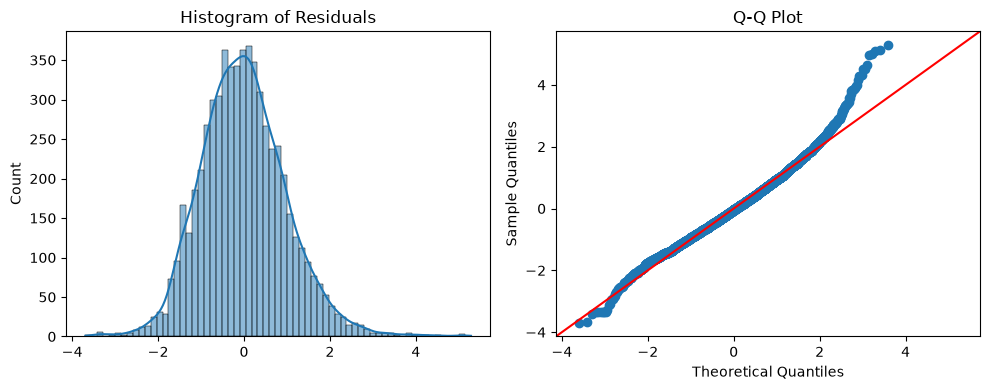

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Histogram + KDE
sns.histplot(standardized_residuals, kde=True, ax=ax[0])
ax[0].set_title("Histogram of Residuals")

# Q-Q plot
sm.qqplot(standardized_residuals, line='45', ax=ax[1])
ax[1].set_title("Q-Q Plot")

plt.tight_layout()
plt.show()

In [7]:
shapiro_test = stats.shapiro(residuals)
print(f"Shapiro-Wilk test: Statistic = {shapiro_test.statistic:.7f}, p-value = {shapiro_test.pvalue:.7f}")

anderson_test = stats.anderson(residuals)
print(f"Anderson-Darling test: Statistic = {anderson_test.statistic:.7f}")
print(f"Significance level: {anderson_test.significance_level}%")
print(f"Critical value: {anderson_test.critical_values}")

Shapiro-Wilk test: Statistic = 0.9862546, p-value = 0.0000000
Anderson-Darling test: Statistic = 11.1837511
Significance level: [15.  10.   5.   2.5  1. ]%
Critical value: [0.561 0.631 0.752 0.873 1.035]


C:\Users\seans\miniconda3\envs\wfu_ml\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 6128.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\seans\AppData\Local\Temp\ipykernel_25852\3805566563.py:4: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson_test = stats.anderson(residuals)


### Independence of Errors

In [8]:
dw_stat = sm.stats.stattools.durbin_watson(residuals)
print(f"Durbin-Watson statistic: {dw_stat:.7f}")

Durbin-Watson statistic: 1.9856941


### Multicollinearity

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = X_selected.columns
vif_data["VIF"] = [variance_inflation_factor(X_selected.values, i) for i in range(X_selected.shape[1])]

print(vif_data)

                               feature       VIF
0                                const  1.000000
1                         accommodates  4.438777
2                             bedrooms  9.450331
3                       minimum_nights  1.075489
4                 review_scores_rating  1.138795
5       calculated_host_listings_count  1.127815
6                          has_hot_tub  1.388048
7                              has_gym  1.492464
8                        has_game_room  1.166202
9                         pets_allowed  1.076347
10               has_city_skyline_view  1.120729
11                           bathrooms  7.954510
12                         shared_bath  1.219373
13    review_scores_rating_was_missing  1.251763
14                 host_is_superhost_t  1.165255
15  neighbourhood_cleansed_District 10  1.104132
16  neighbourhood_cleansed_District 13  1.047734
17  neighbourhood_cleansed_District 15  1.785597
18  neighbourhood_cleansed_District 16  1.145748
19  neighbourhood_cl

Bedrooms (9.45) and bathrooms (7.95) are above the stricter cutoff of 5 but below the common cutoff of 10, which makes sense because bigger listings have more of both. They are kept because both are core price drivers and no VIF exceeds 10. Since no variables were removed, the model is unchanged, and the test set will be built and predicted with it.

### Predictions

## Predictions

No features were removed after the VIF check, so model is unchanged and is used directly. The test set gets the same preprocessing as the training set, using the training medians and the training dummy columns.

In [10]:
# Test set: same steps as the training set (bathrooms were already converted before the split)
X_test = test.drop(columns=['log_price', 'price_quote_price_per_night', 'price_outlier_flag']).copy()
y_test = test['log_price']

# Impute with the TRAIN medians and add the same missing flags
for col, med in medians.items():
    X_test[f'{col}_was_missing'] = X_test[col].isnull().astype(int)
    X_test[col] = X_test[col].fillna(med)

# Dummy variables, then line up the columns with the training data (a category missing from test becomes 0)
X_test = pd.get_dummies(X_test, drop_first=True).astype(float)
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# Keep the 34 selected features and add the constant
X_test_selected = sm.add_constant(X_test[selected_features], has_constant='add')

# Checks
print(X_test_selected.shape, y_test.shape)
print("Missing values left:", int(X_test_selected.isnull().sum().sum()))
print("Columns match model:", list(X_test_selected.columns) == list(X_selected.columns))

(2043, 35) (2043,)
Missing values left: 0
Columns match model: True


In [11]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

lr_pred = model.predict(X_test_selected)   # predictions on the log_price scale

# Log scale (what the model was fit on)
print("Log scale")
print(f"  R-squared: {r2_score(y_test, lr_pred):.4f}")
print(f"  RMSE:      {np.sqrt(mean_squared_error(y_test, lr_pred)):.4f}")
print(f"  MAE:       {mean_absolute_error(y_test, lr_pred):.4f}")

# Dollar scale (convert back from log)
actual_price = np.exp(y_test)
pred_price = np.exp(lr_pred)
print("\nDollar scale (per night)")
print(f"  RMSE: ${np.sqrt(mean_squared_error(actual_price, pred_price)):,.2f}")
print(f"  MAE:  ${mean_absolute_error(actual_price, pred_price):,.2f}")
print(f"  MAPE: {mean_absolute_percentage_error(actual_price, pred_price):.1%}")

Log scale
  R-squared: 0.6138
  RMSE:      0.3703
  MAE:       0.2894

Dollar scale (per night)
  RMSE: $210.32
  MAE:  $117.35
  MAPE: 29.5%


### Outliers and Influential Observations

In [12]:
from statsmodels.stats.outliers_influence import OLSInfluence

# Influence summary
influence = OLSInfluence(model)

# Standardized (Studentized) Residuals
std_resid = influence.resid_studentized_internal

# Flag potential outliers
outliers = np.where(np.abs(std_resid) > 3)[0]
print(f"Potential outliers (|standardized residual| > 3): {outliers.tolist()}")

Potential outliers (|standardized residual| > 3): [17, 20, 52, 61, 332, 506, 578, 647, 1079, 1565, 1628, 1683, 1730, 1893, 1940, 2043, 2835, 2883, 2932, 3058, 3062, 3069, 3145, 3209, 3456, 3516, 3525, 3546, 3712, 3878, 3897, 4105, 4119, 4519, 4705, 4750, 4867, 4893, 4930, 5055, 5127, 5149, 5208, 5508, 5518, 5548, 5669, 5824, 5845, 6102]


In [13]:
leverage = influence.hat_matrix_diag

# Common threshold: 2*(k+1)/n, where k = number of predictors (including dummies), n = samples
n = model.nobs
k = model.df_model
leverage_threshold = 2 * (k + 1) / n
high_leverage = np.where(leverage > leverage_threshold)[0]
print(f"High leverage points (leverage > {leverage_threshold:.3f}): {high_leverage.tolist()}")

High leverage points (leverage > 0.011): [20, 35, 50, 69, 90, 117, 133, 149, 168, 181, 198, 234, 238, 242, 252, 267, 279, 285, 288, 292, 296, 324, 330, 337, 341, 342, 375, 382, 384, 411, 420, 439, 440, 465, 468, 471, 486, 506, 520, 523, 550, 574, 585, 597, 598, 601, 621, 641, 646, 654, 666, 673, 705, 731, 734, 745, 804, 818, 844, 849, 867, 911, 923, 924, 965, 967, 982, 987, 988, 1060, 1073, 1075, 1077, 1096, 1114, 1181, 1188, 1193, 1194, 1195, 1222, 1233, 1262, 1291, 1298, 1299, 1314, 1319, 1360, 1369, 1375, 1394, 1403, 1405, 1421, 1441, 1452, 1509, 1529, 1559, 1565, 1590, 1600, 1610, 1612, 1642, 1648, 1664, 1665, 1694, 1703, 1706, 1719, 1720, 1722, 1750, 1764, 1806, 1820, 1845, 1855, 1897, 1899, 1914, 1933, 1940, 1953, 1971, 1973, 1978, 1984, 1997, 2002, 2016, 2020, 2021, 2036, 2062, 2064, 2074, 2102, 2167, 2176, 2182, 2198, 2221, 2269, 2291, 2318, 2322, 2332, 2340, 2347, 2356, 2382, 2386, 2404, 2422, 2436, 2441, 2447, 2449, 2454, 2475, 2487, 2495, 2506, 2531, 2546, 2549, 2551, 2557, 

In [14]:
cooks_d = influence.cooks_distance[0]
influential_points = np.where(cooks_d > 4 / n)[0]
print(f"Influential points (Cook's D > {4/n:.3f}): {influential_points.tolist()}")

Influential points (Cook's D > 0.001): [17, 20, 35, 38, 52, 61, 79, 122, 170, 198, 201, 243, 256, 279, 285, 296, 324, 330, 332, 337, 342, 374, 386, 465, 474, 506, 574, 578, 598, 601, 621, 647, 731, 734, 757, 764, 773, 786, 831, 834, 849, 869, 923, 943, 965, 987, 999, 1063, 1079, 1096, 1129, 1158, 1181, 1187, 1188, 1193, 1222, 1238, 1250, 1262, 1296, 1299, 1319, 1350, 1362, 1369, 1394, 1397, 1403, 1405, 1441, 1444, 1521, 1532, 1559, 1565, 1590, 1600, 1628, 1664, 1683, 1694, 1704, 1730, 1756, 1757, 1764, 1797, 1806, 1820, 1845, 1855, 1893, 1899, 1940, 1984, 2002, 2020, 2025, 2036, 2043, 2062, 2064, 2090, 2092, 2135, 2167, 2198, 2221, 2226, 2262, 2269, 2288, 2291, 2332, 2340, 2356, 2386, 2447, 2454, 2475, 2531, 2546, 2557, 2612, 2632, 2633, 2661, 2668, 2711, 2715, 2721, 2733, 2766, 2783, 2801, 2835, 2836, 2861, 2883, 2896, 2932, 2969, 2995, 3015, 3019, 3028, 3056, 3058, 3062, 3069, 3075, 3087, 3091, 3097, 3115, 3119, 3145, 3149, 3173, 3183, 3209, 3257, 3270, 3299, 3337, 3351, 3367, 3370, 

C:\Users\seans\miniconda3\envs\wfu_ml\Lib\site-packages\numpy\linalg\_linalg.py:2406: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


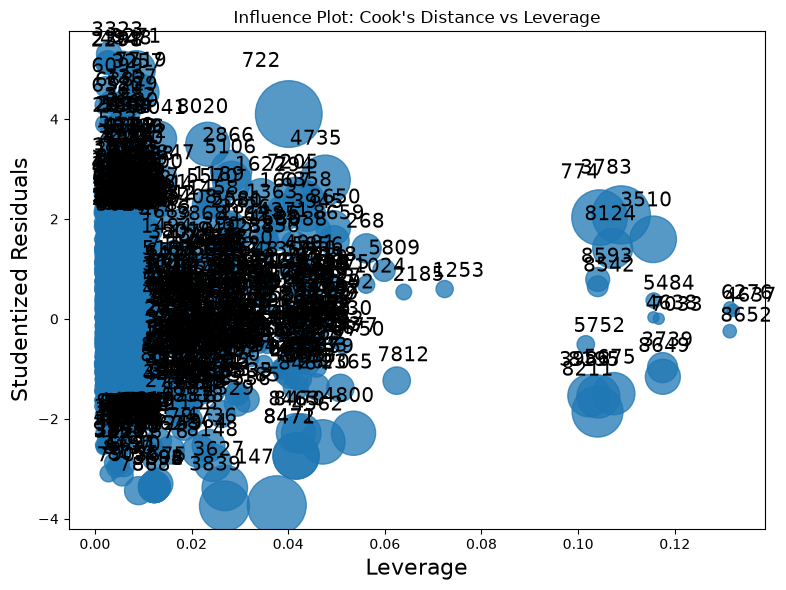

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.influence_plot(model, criterion="cooks", ax=ax)
plt.title("Influence Plot: Cook's Distance vs Leverage")
plt.tight_layout()
plt.show()

In [16]:
diagnostics = pd.DataFrame({
    'y': model.model.endog,
    'fitted': model.fittedvalues,
    'resid': model.resid,
    'std_resid': std_resid,
    'leverage': leverage,
    'cooks_d': cooks_d
})

# Sort by most influential
print("\nTop 5 most influential observations:")
print(diagnostics.sort_values('cooks_d', ascending=False).head())


Top 5 most influential observations:
             y    fitted     resid  std_resid  leverage   cooks_d
722   6.944569  5.397004  1.547566   4.094607  0.040116  0.020020
147   3.632045  5.042222 -1.410178  -3.726287  0.037635  0.015514
3783  5.560682  4.803235  0.757446   2.080016  0.108923  0.015110
774   6.247404  5.507151  0.740253   2.027694  0.104427  0.013698
8211  4.382027  5.059618 -0.677592  -1.855623  0.104014  0.011421


### Sensitivity check: refit without the 5 most influential listings

The five listings with the highest Cook's distance are removed and the model is refit. If the coefficients and test accuracy barely change, the model is stable and those listings do not drive the results. The original model is left unchanged.

In [17]:
# Refit without the 5 most influential training listings
top5 = diagnostics.sort_values('cooks_d', ascending=False).head(5).index
print("Removed listings:", top5.tolist())

X_sens = X_selected.drop(index=top5)
y_sens = y.drop(index=top5)
model_sens = sm.OLS(y_sens, X_sens).fit()

# Coefficient comparison
comp = pd.DataFrame({
    'coef_full': model.params,
    'coef_without_top5': model_sens.params,
    'p_full': model.pvalues,
    'p_without_top5': model_sens.pvalues
})
comp['change'] = comp['coef_without_top5'] - comp['coef_full']
comp['change_in_std_errors'] = comp['change'] / model.bse    # size of the shift relative to the coefficient's uncertainty
comp['sign_flip'] = np.sign(comp['coef_full']) != np.sign(comp['coef_without_top5'])
comp['significance_flip'] = (comp['p_full'] < 0.05) != (comp['p_without_top5'] < 0.05)

print("\nLargest coefficient shifts (in standard errors):")
print(comp.reindex(comp['change_in_std_errors'].abs().sort_values(ascending=False).index).head(8).round(4))
print("\nSign flips:", int(comp['sign_flip'].sum()), "| Significance flips:", int(comp['significance_flip'].sum()))

# Fit and test-set accuracy side by side
def test_metrics(m):
    pred = m.predict(X_test_selected)
    return {
        'R2 test (log)': r2_score(y_test, pred),
        'MAE test (log)': mean_absolute_error(y_test, pred),
        'MAE test ($)': mean_absolute_error(np.exp(y_test), np.exp(pred)),
        'MAPE test': mean_absolute_percentage_error(np.exp(y_test), np.exp(pred)),
        'R2 train': m.rsquared
    }

print("\nFit comparison:")
print(pd.DataFrame({'full model': test_metrics(model), 'without top 5': test_metrics(model_sens)}).round(4))

Removed listings: [722, 147, 3783, 774, 8211]

Largest coefficient shifts (in standard errors):
                                    coef_full  coef_without_top5  p_full  \
neighbourhood_cleansed_District 32    -0.4979            -0.6171  0.0001   
neighbourhood_cleansed_District 10    -0.2673            -0.3331  0.0008   
neighbourhood_cleansed_District 29    -0.3142            -0.2661  0.0000   
const                                  4.7994             4.7815  0.0000   
review_scores_rating                   0.0819             0.0855  0.0001   
property_group_House                   0.0728             0.0705  0.0000   
property_group_Hotel/Resort            0.4984             0.5047  0.0000   
neighbourhood_cleansed_District 15    -0.2488            -0.2514  0.0000   

                                    p_without_top5  change  \
neighbourhood_cleansed_District 32          0.0000 -0.1192   
neighbourhood_cleansed_District 10          0.0000 -0.0658   
neighbourhood_cleansed_District 2